# Assignment No. 5 — Regression and Classification

**Dataset:** Student performance (200 students), generated in the code with a fixed random seed so results are reproducible and no external file is needed.

| Feature | Description |
|---|---|
| Study Hours | Daily study hours |
| Attendance | Attendance percentage |
| Previous Score | Score in the previous exam |
| Sleep Hours | Average sleep per night |
| Marks | Final marks (target for regression) |

## Step 0: Import libraries

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import PolynomialFeatures, StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.metrics import (mean_absolute_error, mean_squared_error, r2_score,
                             accuracy_score, confusion_matrix, classification_report)

sns.set_theme(style="whitegrid")
np.random.seed(42)

## Dataset: Student performance

In [3]:
n = 200
study_hours    = np.round(np.random.uniform(1, 10, n), 1)
attendance     = np.round(np.random.uniform(50, 100, n), 0)
previous_score = np.round(np.random.uniform(35, 95, n), 0)
sleep_hours    = np.round(np.random.uniform(4, 9, n), 1)

# Marks depend on all four features; study hours has diminishing returns (non-linear effect)
marks = (-18
         + 6.0 * study_hours - 0.3 * study_hours**2
         + 0.25 * attendance
         + 0.45 * previous_score
         + 1.0 * sleep_hours
         + np.random.normal(0, 3, n))
marks = np.clip(np.round(marks, 1), 0, 100)

df = pd.DataFrame({
    "Study Hours": study_hours,
    "Attendance": attendance,
    "Previous Score": previous_score,
    "Sleep Hours": sleep_hours,
    "Marks": marks,
})

# Binary target (Pass/Fail) and 3-class target (Low/Medium/High)
df["Result"] = np.where(df["Marks"] >= 50, 1, 0)                  # 1 = Pass, 0 = Fail
df["Performance"] = pd.cut(df["Marks"], bins=[-1, 50, 65, 101], right=False,
                           labels=["Low", "Medium", "High"])

print("Shape:", df.shape)
print()
print(df["Result"].value_counts().rename({1: "Pass", 0: "Fail"}))
print()
print(df["Performance"].value_counts())
df.head(10)

Shape: (200, 7)

Result
Pass    153
Fail     47
Name: count, dtype: int64

Performance
Medium    94
High      59
Low       47
Name: count, dtype: int64


,Study Hours,Attendance,Previous Score,Sleep Hours,Marks,Result,Performance
0,4.4,82.0,41.0,4.8,44.0,0,Low
1,9.6,54.0,89.0,5.4,72.3,1,High
2,7.6,58.0,65.0,4.9,64.6,1,Medium
3,6.4,95.0,85.0,4.4,78.5,1,High
4,2.4,80.0,54.0,4.6,48.4,0,Low
5,2.4,50.0,89.0,6.3,52.0,1,Medium
6,1.5,55.0,58.0,5.0,32.2,0,Low
7,8.8,83.0,36.0,5.8,53.9,1,Medium
8,6.4,50.0,89.0,6.5,67.3,1,High
9,7.4,58.0,40.0,7.5,53.3,1,Medium


In [4]:
print("Missing values:", df.isnull().sum().sum())
df.describe()

Missing values: 0


,Study Hours,Attendance,Previous Score,Sleep Hours,Marks,Result
count,200.000000,200.000000,200.00000,200.000000,200.000000,200.000000
mean,5.358500,75.260000,66.22500,6.391500,58.410500,0.765000
std,2.655842,14.675807,18.42585,1.392614,11.678316,0.425063
min,1.000000,50.000000,36.00000,4.100000,26.300000,0.000000
25%,3.100000,63.000000,50.00000,5.200000,51.225000,1.000000
50%,5.450000,77.000000,66.50000,6.350000,59.150000,1.000000
75%,7.800000,87.000000,84.00000,7.625000,66.300000,1.000000
max,9.900000,100.000000,95.00000,8.900000,87.200000,1.000000


## Question 1: Multivariate Linear Regression (4 independent variables)

In [5]:
features = ["Study Hours", "Attendance", "Previous Score", "Sleep Hours"]
X = df[features]
y = df["Marks"]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

lin_reg = LinearRegression()
lin_reg.fit(X_train, y_train)
y_pred_lin = lin_reg.predict(X_test)

print("Intercept:", round(lin_reg.intercept_, 3))
for f, c in zip(features, lin_reg.coef_):
    print(f"  {f:<15} coefficient = {c:.3f}")

print()
print(f"R2 Score : {r2_score(y_test, y_pred_lin):.4f}")
print(f"MAE      : {mean_absolute_error(y_test, y_pred_lin):.3f}")
print(f"RMSE     : {np.sqrt(mean_squared_error(y_test, y_pred_lin)):.3f}")

Intercept: -8.535
  Study Hours     coefficient = 2.795
  Attendance      coefficient = 0.231
  Previous Score  coefficient = 0.442
  Sleep Hours     coefficient = 0.809

R2 Score : 0.9216
MAE      : 2.825
RMSE     : 3.534


## Question 2: Polynomial Regression and comparison with Linear Regression

In [6]:
results = []
poly_models = {}

# Degree 1 is the ordinary linear model; degrees 2 and 3 are polynomial models
for degree in [1, 2, 3]:
    model = make_pipeline(PolynomialFeatures(degree, include_bias=False),
                          StandardScaler(),
                          LinearRegression())
    model.fit(X_train, y_train)
    poly_models[degree] = model
    pred_train = model.predict(X_train)
    pred_test = model.predict(X_test)
    results.append({
        "Model": "Linear Regression" if degree == 1 else f"Polynomial (degree {degree})",
        "Train R2": r2_score(y_train, pred_train),
        "Test R2": r2_score(y_test, pred_test),
        "Test MAE": mean_absolute_error(y_test, pred_test),
        "Test RMSE": np.sqrt(mean_squared_error(y_test, pred_test)),
    })

comparison = pd.DataFrame(results).round(4)
comparison

,Model,Train R2,Test R2,Test MAE,Test RMSE
0,Linear Regression,0.9034,0.9216,2.8253,3.5341
1,Polynomial (degree 2),0.9349,0.9509,2.2594,2.7969
2,Polynomial (degree 3),0.9419,0.9376,2.6732,3.1525


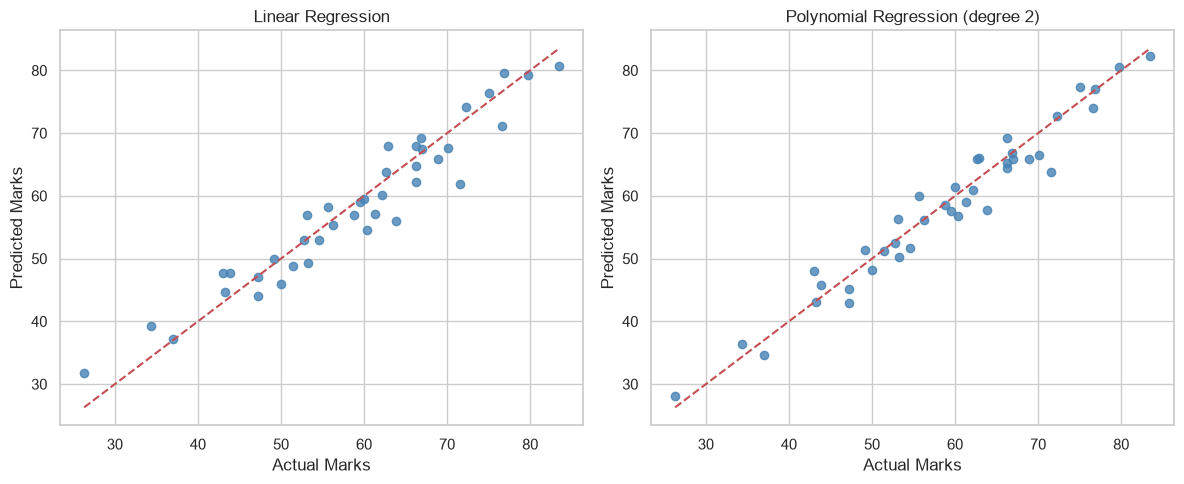

In [7]:
y_pred_poly = poly_models[2].predict(X_test)     # degree-2 polynomial model used for later comparison

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
for ax, pred, title in zip(axes, [y_pred_lin, y_pred_poly],
                           ["Linear Regression", "Polynomial Regression (degree 2)"]):
    ax.scatter(y_test, pred, color="steelblue", alpha=0.8)
    ax.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], "r--")
    ax.set_title(title)
    ax.set_xlabel("Actual Marks")
    ax.set_ylabel("Predicted Marks")
plt.tight_layout()
plt.show()

**Observation:** The data has a diminishing-returns effect of study hours, so the polynomial model (degree 2) fits better than the plain linear model (higher R² and lower error on the test set). Degree 3 adds many extra terms with little gain, which shows the risk of overfitting (compare the train and test R²).

## Question 3: Logistic Regression — Pass / Fail

In [8]:
y_bin = df["Result"]
y_multi = df["Performance"].astype(str)

# One shared split for both classifiers, so they are tested on the same students
Xb_train, Xb_test, yb_train, yb_test, ym_train, ym_test = train_test_split(
    X, y_bin, y_multi, test_size=0.2, random_state=42, stratify=y_multi)

log_reg = make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000))
log_reg.fit(Xb_train, yb_train)
yb_pred = log_reg.predict(Xb_test)

print(f"Accuracy: {accuracy_score(yb_test, yb_pred):.4f}")
print()
print("Classification report:")
print(classification_report(yb_test, yb_pred, target_names=["Fail", "Pass"]))

Accuracy: 0.8500

Classification report:
              precision    recall  f1-score   support

        Fail       0.64      0.78      0.70         9
        Pass       0.93      0.87      0.90        31

    accuracy                           0.85        40
   macro avg       0.78      0.82      0.80        40
weighted avg       0.86      0.85      0.86        40



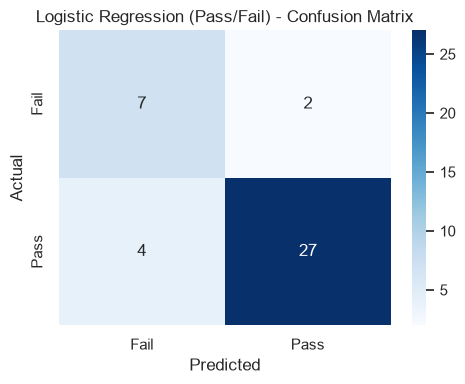

In [9]:
cm = confusion_matrix(yb_test, yb_pred)
plt.figure(figsize=(5, 4))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=["Fail", "Pass"], yticklabels=["Fail", "Pass"])
plt.title("Logistic Regression (Pass/Fail) - Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.tight_layout()
plt.show()

## Question 4: Multiclass Logistic Regression — Low / Medium / High

In [10]:
# Same train/test split as Question 3 (Xb_train / Xb_test), with the 3-class target
multi_reg = make_pipeline(StandardScaler(),
                          LogisticRegression(max_iter=1000))   # lbfgs solver -> multinomial (softmax)
multi_reg.fit(Xb_train, ym_train)
ym_pred = multi_reg.predict(Xb_test)

labels = ["Low", "Medium", "High"]
print(f"Accuracy: {accuracy_score(ym_test, ym_pred):.4f}")
print()
print("Classification report:")
print(classification_report(ym_test, ym_pred, labels=labels))

Accuracy: 0.7750

Classification report:
              precision    recall  f1-score   support

         Low       0.64      0.78      0.70         9
      Medium       0.78      0.74      0.76        19
        High       0.91      0.83      0.87        12

    accuracy                           0.78        40
   macro avg       0.77      0.78      0.78        40
weighted avg       0.79      0.78      0.78        40



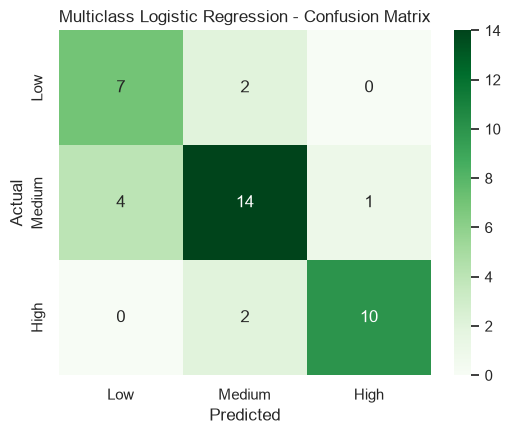

In [11]:
cm = confusion_matrix(ym_test, ym_pred, labels=labels)
plt.figure(figsize=(5.5, 4.5))
sns.heatmap(cm, annot=True, fmt="d", cmap="Greens", xticklabels=labels, yticklabels=labels)
plt.title("Multiclass Logistic Regression - Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.tight_layout()
plt.show()

## Question 5: Compare predictions of the models with actual values

### 5. a. Regression models (Marks)

In [12]:
reg_compare = pd.DataFrame({
    "Actual Marks": y_test.values,
    "Linear Pred": np.round(y_pred_lin, 1),
    "Polynomial Pred": np.round(y_pred_poly, 1),
})
reg_compare["Linear Error"] = (reg_compare["Actual Marks"] - reg_compare["Linear Pred"]).round(1)
reg_compare["Polynomial Error"] = (reg_compare["Actual Marks"] - reg_compare["Polynomial Pred"]).round(1)
reg_compare.head(15)

,Actual Marks,Linear Pred,Polynomial Pred,Linear Error,Polynomial Error
0,60.3,54.6,56.8,5.7,3.5
1,43.0,47.7,48.0,-4.7,-5.0
2,63.8,56.0,57.8,7.8,6.0
3,66.2,64.8,65.3,1.4,0.9
4,26.3,31.8,28.1,-5.5,-1.8
5,59.5,59.0,57.6,0.5,1.9
6,76.8,79.6,77.1,-2.8,-0.3
7,58.8,56.9,58.5,1.9,0.3
8,66.3,67.9,69.2,-1.6,-2.9
9,83.5,80.8,82.3,2.7,1.2


Mean absolute error on the test set:
  Linear Regression     : 2.825
  Polynomial (degree 2) : 2.259


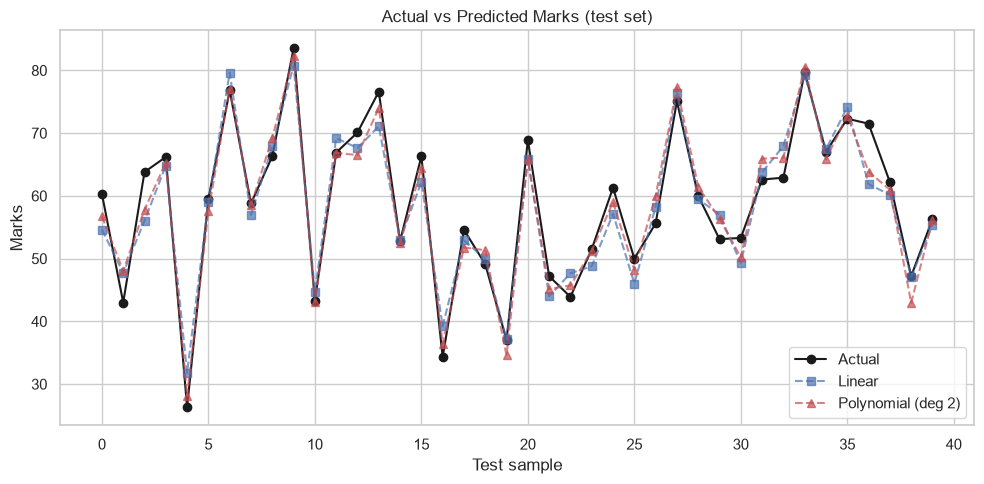

In [13]:
print("Mean absolute error on the test set:")
print(f"  Linear Regression     : {mean_absolute_error(y_test, y_pred_lin):.3f}")
print(f"  Polynomial (degree 2) : {mean_absolute_error(y_test, y_pred_poly):.3f}")

plt.figure(figsize=(10, 5))
idx = np.arange(len(y_test))
plt.plot(idx, y_test.values, "ko-", label="Actual")
plt.plot(idx, y_pred_lin, "b--s", label="Linear", alpha=0.7)
plt.plot(idx, y_pred_poly, "r--^", label="Polynomial (deg 2)", alpha=0.7)
plt.title("Actual vs Predicted Marks (test set)")
plt.xlabel("Test sample")
plt.ylabel("Marks")
plt.legend()
plt.tight_layout()
plt.show()

### 5. b. Classification models (Pass/Fail and Low/Medium/High)

In [14]:
cls_compare = pd.DataFrame({
    "Actual Result": np.where(yb_test.values == 1, "Pass", "Fail"),
    "Predicted Result": np.where(yb_pred == 1, "Pass", "Fail"),
}, index=yb_test.index)
cls_compare["Actual Performance"] = ym_test.values
cls_compare["Predicted Performance"] = ym_pred
cls_compare["Marks"] = df.loc[yb_test.index, "Marks"]
cls_compare["Result Correct"] = cls_compare["Actual Result"] == cls_compare["Predicted Result"]
cls_compare["Performance Correct"] = cls_compare["Actual Performance"] == cls_compare["Predicted Performance"]
cls_compare.head(15)

,Actual Result,Predicted Result,Actual Performance,Predicted Performance,Marks,Result Correct,Performance Correct
52,Pass,Pass,High,High,68.0,True,True
115,Pass,Pass,Medium,Medium,59.5,True,True
74,Pass,Pass,High,Medium,67.0,True,False
111,Fail,Fail,Low,Low,39.7,True,True
197,Pass,Pass,Medium,Medium,59.2,True,True
76,Pass,Pass,Medium,Medium,56.3,True,True
163,Pass,Fail,Medium,Low,51.7,False,False
162,Pass,Pass,Medium,Medium,52.7,True,True
193,Pass,Pass,Medium,Medium,63.9,True,True
92,Pass,Pass,Medium,Medium,61.6,True,True


In [15]:
wrong = cls_compare[~cls_compare["Result Correct"] | ~cls_compare["Performance Correct"]]
print("Test samples            :", len(cls_compare))
print("Pass/Fail correct       :", cls_compare["Result Correct"].sum())
print("Performance correct     :", cls_compare["Performance Correct"].sum())
print()
print("Misclassified samples:")
wrong

Test samples            : 40
Pass/Fail correct       : 34
Performance correct     : 31

Misclassified samples:


,Actual Result,Predicted Result,Actual Performance,Predicted Performance,Marks,Result Correct,Performance Correct
74,Pass,Pass,High,Medium,67.0,True,False
163,Pass,Fail,Medium,Low,51.7,False,False
37,Fail,Pass,Low,Medium,48.0,False,False
156,Fail,Pass,Low,Medium,46.3,False,False
135,Pass,Pass,High,Medium,71.5,True,False
105,Pass,Fail,Medium,Low,51.5,False,False
142,Pass,Fail,Medium,Low,58.1,False,False
60,Pass,Fail,Medium,Low,50.0,False,False
19,Pass,Pass,Medium,High,62.5,True,False


### Summary of all models

In [16]:
summary = pd.DataFrame({
    "Model": ["Multivariate Linear Regression", "Polynomial Regression (deg 2)",
              "Logistic Regression (Pass/Fail)", "Multiclass Logistic Regression"],
    "Task": ["Predict Marks", "Predict Marks", "Pass/Fail", "Low/Medium/High"],
    "Metric": ["R2", "R2", "Accuracy", "Accuracy"],
    "Score": [r2_score(y_test, y_pred_lin), r2_score(y_test, y_pred_poly),
              accuracy_score(yb_test, yb_pred), accuracy_score(ym_test, ym_pred)],
}).round(4)
summary

,Model,Task,Metric,Score
0,Multivariate Linear Regression,Predict Marks,R2,0.9216
1,Polynomial Regression (deg 2),Predict Marks,R2,0.9509
2,Logistic Regression (Pass/Fail),Pass/Fail,Accuracy,0.8500
3,Multiclass Logistic Regression,Low/Medium/High,Accuracy,0.7750


## Conclusion

- The multivariate linear regression (4 variables) predicts marks well.
- Polynomial regression (degree 2) improves on it because study hours has a non-linear effect; degree 3 shows signs of overfitting.
- Logistic regression classifies Pass/Fail with good accuracy (85%); the errors are students whose marks are close to the pass mark of 50.
- Multiclass logistic regression separates Low / Medium / High performance; most errors happen between neighbouring classes (e.g. Medium vs High).
- Predictions were compared with actual values in tables, plots and confusion matrices.